In [1]:

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

import os
for dirname, _, filenames in os.walk('D:\HACKATHON\Team-Chaos\models\pothole-dataset'):
    for filename in filenames:
        print(os.path.join(dirname, filename))


D:\HACKATHON\Team-Chaos\models\pothole-dataset\check.jpg
D:\HACKATHON\Team-Chaos\models\pothole-dataset\try2.jpg
D:\HACKATHON\Team-Chaos\models\pothole-dataset\try3.jpg
D:\HACKATHON\Team-Chaos\models\pothole-dataset\normal\1.jpg
D:\HACKATHON\Team-Chaos\models\pothole-dataset\normal\10.jpg
D:\HACKATHON\Team-Chaos\models\pothole-dataset\normal\100.jpg
D:\HACKATHON\Team-Chaos\models\pothole-dataset\normal\101.jpg
D:\HACKATHON\Team-Chaos\models\pothole-dataset\normal\102.jpg
D:\HACKATHON\Team-Chaos\models\pothole-dataset\normal\103.jpg
D:\HACKATHON\Team-Chaos\models\pothole-dataset\normal\104.jpg
D:\HACKATHON\Team-Chaos\models\pothole-dataset\normal\105.jpg
D:\HACKATHON\Team-Chaos\models\pothole-dataset\normal\106.jpg
D:\HACKATHON\Team-Chaos\models\pothole-dataset\normal\107.jpg
D:\HACKATHON\Team-Chaos\models\pothole-dataset\normal\108.jpg
D:\HACKATHON\Team-Chaos\models\pothole-dataset\normal\109.jpg
D:\HACKATHON\Team-Chaos\models\pothole-dataset\normal\11.jpg
D:\HACKATHON\Team-Chaos\model

**IMPORTING LIBRARIES**

In [2]:

from keras.preprocessing.image import ImageDataGenerator
import cv2
import matplotlib.pyplot as plt
import tensorflow as tf

**CHECKING IMAGES FOR CONFIRMATION**

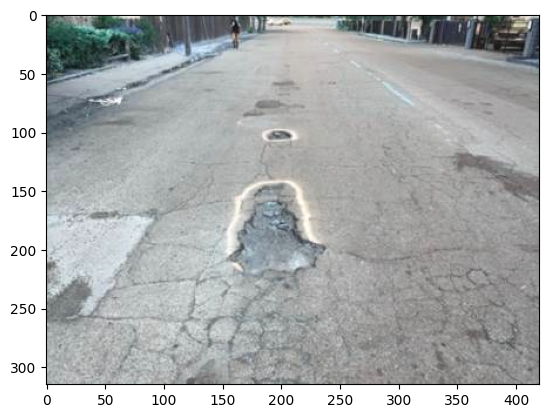

In [3]:
plt.imshow(cv2.imread("D:/HACKATHON/Team-Chaos/models/pothole-dataset/potholes/125.jpg"))

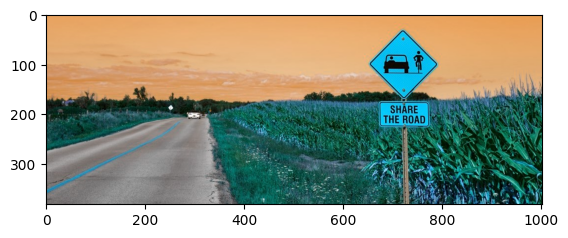

In [4]:
plt.imshow(cv2.imread("D:/HACKATHON/Team-Chaos/models/pothole-dataset/normal/125.jpg"))

****Splitting dataset into training and validation and preprocessing the training set****

In [5]:
train_datagen = ImageDataGenerator(rescale = 1./255,
                                   shear_range = 0.2,
                                   zoom_range = 0.2,
                                   horizontal_flip = True,
                                   validation_split=0.2)
training_set = train_datagen.flow_from_directory('D:/HACKATHON/Team-Chaos/models/pothole-dataset',
                                                 target_size = (64, 64),
                                                 batch_size = 32,
                                                 class_mode = 'binary',
                                                 subset="training")

Found 546 images belonging to 2 classes.


**Preprocessing the validation set**

In [6]:
validation_generator = train_datagen.flow_from_directory(
    "D:/HACKATHON/Team-Chaos/models/pothole-dataset", # same directory as training data
    target_size=(64, 64),
    batch_size=32,
    class_mode='binary',
    subset='validation')

Found 135 images belonging to 2 classes.


**Initialising the CNN**

In [7]:
cnn = tf.keras.models.Sequential()

In [8]:
cnn.add(tf.keras.layers.Conv2D(filters=32, kernel_size=3, activation='relu', input_shape=[64, 64, 3]))

In [9]:
cnn.add(tf.keras.layers.MaxPool2D(pool_size=2, strides=2))

In [10]:
cnn.add(tf.keras.layers.Conv2D(filters=32, kernel_size=3, activation='relu'))
cnn.add(tf.keras.layers.MaxPool2D(pool_size=2, strides=2))

In [11]:
cnn.add(tf.keras.layers.Flatten())

In [12]:
cnn.add(tf.keras.layers.Dense(units=128, activation='relu'))

In [13]:
cnn.add(tf.keras.layers.Dense(units=1, activation='sigmoid'))

**Compiling the CNN**

In [14]:
cnn.compile(optimizer = 'adam', loss = 'binary_crossentropy', metrics = ['accuracy'])

**Training the CNN on the Training set and evaluating it on the Validation set**

In [15]:
import PIL

In [16]:
PIL.Image 

<module 'PIL.Image' from 'd:\\HACKATHON\\venv\\Lib\\site-packages\\PIL\\Image.py'>

In [17]:
import scipy

In [18]:
cnn.fit(x = training_set, validation_data = validation_generator, epochs = 25)

Epoch 1/25
18/18 [==============================] - 38s 2s/step - loss: 0.8409 - accuracy: 0.4963 - val_loss: 0.6886 - val_accuracy: 0.5259
Epoch 2/25
18/18 [==============================] - 30s 2s/step - loss: 0.6427 - accuracy: 0.6667 - val_loss: 0.5567 - val_accuracy: 0.7481
Epoch 3/25
18/18 [==============================] - 19s 1s/step - loss: 0.4851 - accuracy: 0.7985 - val_loss: 0.4408 - val_accuracy: 0.7778
Epoch 4/25
18/18 [==============================] - 23s 1s/step - loss: 0.3909 - accuracy: 0.8370 - val_loss: 0.4212 - val_accuracy: 0.8000
Epoch 5/25
18/18 [==============================] - 30s 2s/step - loss: 0.3137 - accuracy: 0.8755 - val_loss: 0.3645 - val_accuracy: 0.8148
Epoch 6/25
18/18 [==============================] - 15s 827ms/step - loss: 0.2487 - accuracy: 0.8993 - val_loss: 0.3894 - val_accuracy: 0.8370
Epoch 7/25
18/18 [==============================] - 14s 703ms/step - loss: 0.3434 - accuracy: 0.8370 - val_loss: 0.4451 - val_accuracy: 0.8000
Epoch 8/25
18/

In [19]:
# Save the trained model
model_save_path = 'pothole_classifier_model.h5'
cnn.save(model_save_path)
print(f"Model saved to {model_save_path}")

d:\HACKATHON\venv\Lib\site-packages\keras\src\engine\training.py:3000: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


Model saved to pothole_classifier_model.h5


**Part 4 - Making a single prediction**

In [32]:
import numpy as np
from keras.preprocessing import image
test_image = image.load_img('D:/HACKATHON/Team-Chaos/models/pothole-dataset/try3.jpg', target_size = (64, 64))
test_image = image.img_to_array(test_image)
test_image = np.expand_dims(test_image, axis = 0)
result = cnn.predict(test_image)
training_set.class_indices
if result[0][0] == 1:
  prediction = 'pothole'
else:
  prediction = 'normal'

1/1 [==============================] - 0s 32ms/step


In [33]:
print (result[0][0])

0.0


In [34]:
print (prediction)

normal
